In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"abdokholidy87","key":"b707587f168506a7ba5883a5c72c2c67"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip -q chest-xray-pneumonia.zip -d /content/new_chest_data

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:03<00:00, 39.0MB/s]



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Evaluating MobileNetV2...
Found 1193 non-validated image filenames.
 MobileNetV2 Results: Acc=0.7536 | Prec=0.8289 | Rec=0.7621 | AUC=0.8560

Evaluating ResNet50...
Found 1193 non-validated image filenames.
 ResNet50 Results: Acc=0.7779 | Prec=0.8634 | Rec=0.7648 | AUC=0.8836

Evaluating DenseNet121...
Found 1193 non-validated image filenames.
 DenseNet121 Results: Acc=0.7427 | Prec=0.8854 | Rec=0.6747 | AUC=0.8779


 FINAL MODEL COMPARISON (Test Set) 
      Model  Accuracy  Precision (Pneumonia)  Recall (Pneumonia)    AUC
MobileNetV2    0.7536                 0.8289              0.7621 0.8560
   ResNet50    0.7779                 0.8634              0.7648 0.8836
DenseNet121    0.7427                 0.8854              0.6747 0.8779


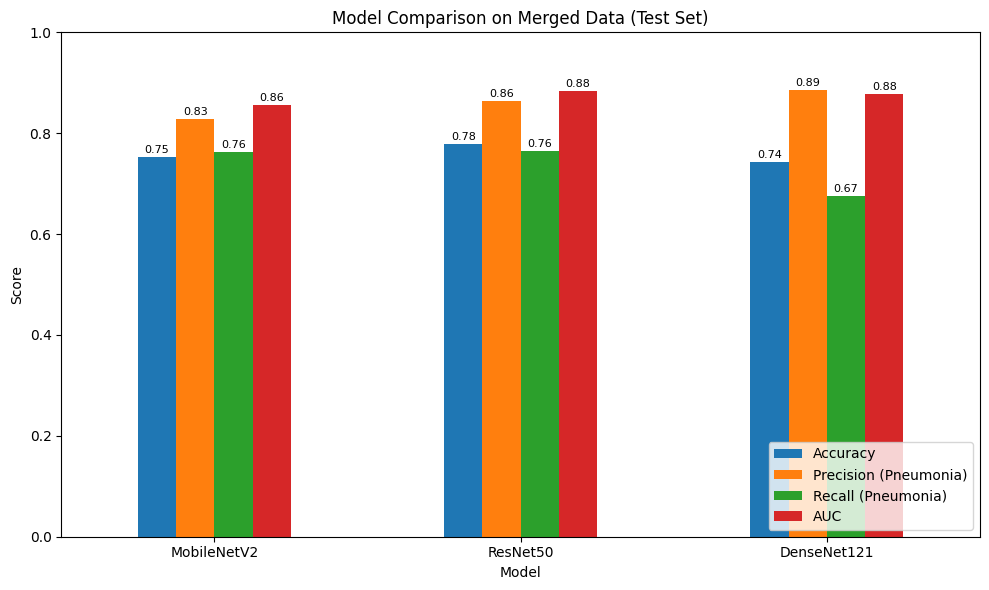

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import mobilenet_v2, resnet50, densenet
from sklearn.metrics import (accuracy_score, classification_report,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from google.colab import drive

# ==========================================
# 0. Configuration & Setup
# ==========================================
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
VAL_FRACTION = 0.15

# Mount Drive
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/Ml_projects/InnoTech_Dataset'
CSV_PATH = os.path.join(BASE_DIR, 'cnn_data.csv')
IMAGES_DIR = os.path.join(BASE_DIR, 'images_224')
KAGGLE_DIR = '/content/new_chest_data/chest_xray'
COLUMNS = ['full_path', 'label_num', 'split', 'source']

# ==========================================
# 1. Recreate the EXACT same Test Set
# ==========================================
# Load Indiana
df_indiana = pd.read_csv(CSV_PATH)
df_indiana['full_path'] = df_indiana['filename'].apply(lambda f: os.path.join(IMAGES_DIR, f))
df_indiana['label_num'] = df_indiana['label'].astype(int)
df_indiana['source'] = 'indiana'
df_indiana = df_indiana[COLUMNS]

# Load Kaggle
rows = []
for split in ['train', 'val', 'test']:
    for label, class_name in enumerate(['NORMAL', 'PNEUMONIA']):
        folder = os.path.join(KAGGLE_DIR, split, class_name)
        if not os.path.isdir(folder):
            continue
        for fname in os.listdir(folder):
            if fname.lower().endswith(('.jpeg', '.jpg', '.png')):
                rows.append((os.path.join(folder, fname), label, split, 'kaggle'))
df_kaggle = pd.DataFrame(rows, columns=COLUMNS)

# Merge
df = pd.concat([df_indiana, df_kaggle], ignore_index=True)
exists = df['full_path'].map(os.path.exists)
df = df[exists].reset_index(drop=True)

# Resplit to get the exact same Test Set (since 'test' split was untouched, it remains the same)
# However, to be perfectly aligned with the training script, we recreate train/val split logic
pool = df[df['split'] != 'test']
strata = pool['source'] + '_' + pool['label_num'].astype(str)
_, val_idx = train_test_split(pool.index, test_size=VAL_FRACTION, stratify=strata, random_state=SEED)
df.loc[pool.index, 'split'] = 'train'
df.loc[val_idx, 'split'] = 'val'

test_df = df[df['split'] == 'test'].reset_index(drop=True)
y_true = test_df['label_num'].values.astype(int)

# ==========================================
# 2. Helper to load and evaluate each model
# ==========================================
def evaluate_saved_model(model_name, preprocess_fn):
    print(f"\n{'='*50}\nEvaluating {model_name}...\n{'='*50}")
    tf.keras.backend.clear_session()
    gc.collect()

    model_path = os.path.join(BASE_DIR, f'{model_name}_merged_fixed.keras')
    if not os.path.exists(model_path):
        print(f" Model {model_name} not found at {model_path}!")
        return None

    # Load the model
    model = tf.keras.models.load_model(model_path)

    # Create test generator
    test_datagen = ImageDataGenerator(preprocessing_function=preprocess_fn)
    test_gen = test_datagen.flow_from_dataframe(
        test_df, x_col='full_path', y_col='label_num',
        target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='raw', shuffle=False, seed=SEED,
        validate_filenames=False
    )

    # Predict
    probs = model.predict(test_gen, verbose=0).ravel()
    y_pred = (probs > 0.5).astype(int)

    # Calculate metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, probs)

    print(f" {model_name} Results: Acc={acc:.4f} | Prec={prec:.4f} | Rec={rec:.4f} | AUC={auc:.4f}")

    # Clear memory
    del model
    gc.collect()

    return {
        'Model': model_name,
        'Accuracy': acc,
        'Precision (Pneumonia)': prec,
        'Recall (Pneumonia)': rec,
        'AUC': auc
    }

# ==========================================
# 3. Run Evaluation for all 3 models
# ==========================================
results = []

# 1. MobileNetV2
res_mob = evaluate_saved_model('MobileNetV2', mobilenet_v2.preprocess_input)
if res_mob: results.append(res_mob)

# 2. ResNet50
res_res = evaluate_saved_model('ResNet50', resnet50.preprocess_input)
if res_res: results.append(res_res)

# 3. DenseNet121
res_den = evaluate_saved_model('DenseNet121', densenet.preprocess_input)
if res_den: results.append(res_den)

# ==========================================
# 4. Final Comparison Table and Plot
# ==========================================
if results:
    results_df = pd.DataFrame(results).round(4)
    print('\n\n FINAL MODEL COMPARISON (Test Set) ')
    print(results_df.to_string(index=False))

    # Plotting
    ax = results_df.set_index('Model').plot(kind='bar', figsize=(10, 6), rot=0)
    plt.title('Model Comparison on Merged Data (Test Set)')
    plt.ylabel('Score')
    plt.ylim(0, 1.0)
    plt.legend(loc='lower right')
    plt.tight_layout()

    # Add value labels on top of bars
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=8)

    plt.show()
else:
    print("No models were evaluated. Please check the file paths.")